# 01 — Problem & Dataset
**Project:** Detecting ChatGPT-Generated Text: A Comparison of Classical Machine Learning, Perplexity-Based and Fine-Tuned Transformer Detectors

This notebook covers Stage 1 of the project:
1. Load the **HC3** dataset (Human ChatGPT Comparison Corpus, Guo et al., 2023).
2. Describe its structure: domains, classes, text lengths.
3. Check data quality: empty texts, generation errors, duplicates.
4. Find **formatting artifacts** that could let a model "cheat".
5. Summarise findings and the preprocessing plan.

In [1]:
import json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = Path('../data/raw')
FIG = Path('../reports/figures'); FIG.mkdir(parents=True, exist_ok=True)
OUT = Path('../data/interim'); OUT.mkdir(parents=True, exist_ok=True)
DOMAINS = ['finance', 'medicine', 'open_qa', 'reddit_eli5', 'wiki_csai']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
COLORS = {'human': '#2a78d6', 'chatgpt': '#e8833a'}

## 1. Loading the data
HC3 stores one **question** per line with a list of **human answers** and a list of **ChatGPT answers**.
We convert it to a "long" table: one row = one answer, with its domain and label (`human` / `chatgpt`).

In [2]:
rows = []
for d in DOMAINS:
    with open(RAW / f'{d}.jsonl', encoding='utf-8') as f:
        for qid, line in enumerate(f):
            r = json.loads(line)
            for a in r['human_answers']:
                rows.append((d, f'{d}_{qid}', r['question'], a or '', 'human'))
            for a in r['chatgpt_answers']:
                rows.append((d, f'{d}_{qid}', r['question'], a or '', 'chatgpt'))

df = pd.DataFrame(rows, columns=['domain', 'qid', 'question', 'text', 'label'])
df['n_words'] = df['text'].str.split().str.len()
print(f'Questions: {df.qid.nunique():,}   Answers: {len(df):,}')
df.head(3)

Questions: 24,322   Answers: 85,449


,domain,qid,question,text,label,n_words
0,finance,finance_0,Historical P/E ratios of small-cap vs. large-c...,There is most likely an error in the WSJ's dat...,human,47
1,finance,finance_0,Historical P/E ratios of small-cap vs. large-c...,Historical price-to-earnings (P/E) ratios for ...,chatgpt,185
2,finance,finance_1,Should you co-sign a personal loan for a frien...,I know this question has a lot of answers alre...,human,157


## 2. Dataset structure: domains and classes

In [3]:
counts = pd.crosstab(df.domain, df.label, margins=True, margins_name='total')
counts['chatgpt_share_%'] = (counts['chatgpt'] / counts['total'] * 100).round(1)
counts

label,chatgpt,human,total,chatgpt_share_%
domain,,,,
finance,4503,3933,8436,53.4
medicine,1337,1248,2585,51.7
open_qa,3561,1187,4748,75.0
reddit_eli5,16660,51336,67996,24.5
wiki_csai,842,842,1684,50.0
total,26903,58546,85449,31.5


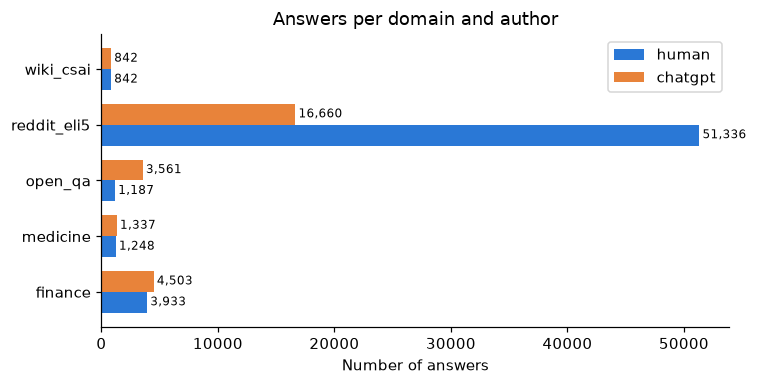

In [4]:
ct = pd.crosstab(df.domain, df.label)[['human', 'chatgpt']]
ax = ct.plot.barh(color=[COLORS['human'], COLORS['chatgpt']], figsize=(7, 3.6), width=0.75)
ax.set_xlabel('Number of answers'); ax.set_ylabel('')
ax.set_title('Answers per domain and author')
for c in ax.containers: ax.bar_label(c, fmt='{:,.0f}', fontsize=8, padding=2)
ax.legend(title=''); plt.tight_layout(); plt.savefig(FIG / 'fig1_class_balance.png'); plt.show()

**Observation.** `reddit_eli5` contains ~80% of all answers and is strongly imbalanced
(about 3 human answers per ChatGPT answer). Other domains are roughly balanced.
→ Without balancing, a model would mostly learn Reddit and favour the `human` class.

## 3. Text length

In [5]:
length = df.groupby(['domain', 'label']).n_words.median().unstack()[['human', 'chatgpt']]
length.columns = ['median words (human)', 'median words (chatgpt)']
length

,median words (human),median words (chatgpt)
domain,,
finance,129.0,205.0
medicine,74.0,184.0
open_qa,27.0,106.0
reddit_eli5,82.0,173.0
wiki_csai,166.0,187.5


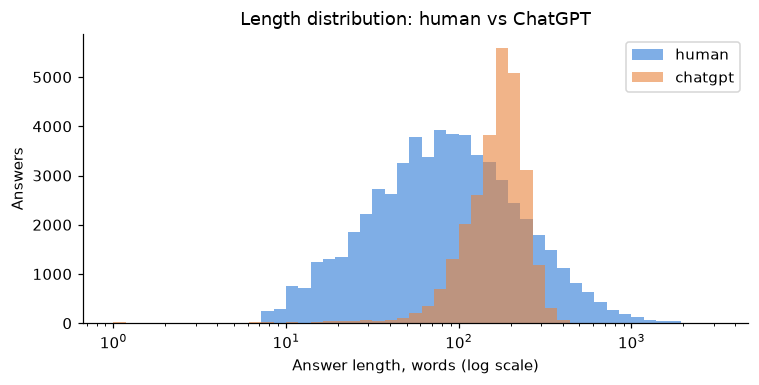

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.logspace(0, 3.5, 50)
for lab in ['human', 'chatgpt']:
    ax.hist(df.loc[df.label == lab, 'n_words'].clip(lower=1), bins=bins, alpha=0.6,
            label=lab, color=COLORS[lab])
ax.set_xscale('log'); ax.set_xlabel('Answer length, words (log scale)'); ax.set_ylabel('Answers')
ax.set_title('Length distribution: human vs ChatGPT'); ax.legend()
plt.tight_layout(); plt.savefig(FIG / 'fig2_length.png'); plt.show()

**Observation.** ChatGPT answers have a narrow, "standard" length (~100–250 words),
while human answers vary from a few words to thousands. In `open_qa` and `medicine` humans write
2–4× shorter answers. → Length alone is a strong signal, so we must check that models learn
more than length.

## 4. Data quality

In [7]:
err_mask = df.text.str.contains('There was an error generating a response|Too many requests', regex=True)
quality = pd.Series({
    'empty or whitespace-only': (df.text.str.strip() == '').sum(),
    'ChatGPT error messages instead of answers': err_mask.sum(),
    'duplicate texts (repeated rows)': df.duplicated('text').sum(),
})
print(quality.to_string())
print()
print('Examples of error messages:')
for t in df.loc[err_mask, 'text'].drop_duplicates().head(3): print('  -', repr(t[:110]))

empty or whitespace-only                       18
ChatGPT error messages instead of answers     100
duplicate texts (repeated rows)              6117

Examples of error messages:
  - '!Your authentication token has expired. Please try signing in again.There was an error generating a response'
  - '!Only one message at a time. Please allow any other responses to complete before sending another message, or w'
  - '!There are several ways to model historical market purchases, depending on the type of market you are interest'


In [8]:
dup = df[df.duplicated('text', keep=False) & (df.text.str.strip() != '')]
print('Duplicated texts by label:'); print(dup.groupby('label').size().to_string())

Duplicated texts by label:
label
chatgpt     1177
human      10908


**Observation.** Some ChatGPT "answers" are actually server error messages,
and there are thousands of duplicated texts. Both must be removed before training,
otherwise the same text can land in train and test (data leakage).

## 5. Formatting artifacts — can a model "cheat"?
Human answers in HC3 come from older NLP datasets that were **tokenized**: spaces were inserted
before punctuation (`word , word`, `do n't`). ChatGPT answers were collected differently and lost line breaks
(`end.Next sentence`). These differences have nothing to do with *who wrote* the text.

In [9]:
patterns = {
    'space before punctuation  ( " ," " ." )': r' [,.!?;:]',
    "split contractions  ( do n't )": r" n't\b",
    'missing space after period  ( end.Next )': r'[a-z]\.[A-Z]',
    'contains a line break': r'\n',
}
art = pd.DataFrame({name: df.groupby('label').text.apply(lambda s, p=p: s.str.contains(p, regex=True).mean() * 100)
                    for name, p in patterns.items()}).T[['human', 'chatgpt']].round(1)
art.columns = ['% of human answers', '% of ChatGPT answers']
art

,% of human answers,% of ChatGPT answers
"space before punctuation ( "" ,"" "" ."" )",88.8,0.3
split contractions ( do n't ),34.1,0.0
missing space after period ( end.Next ),1.3,19.7
contains a line break,1.1,30.3


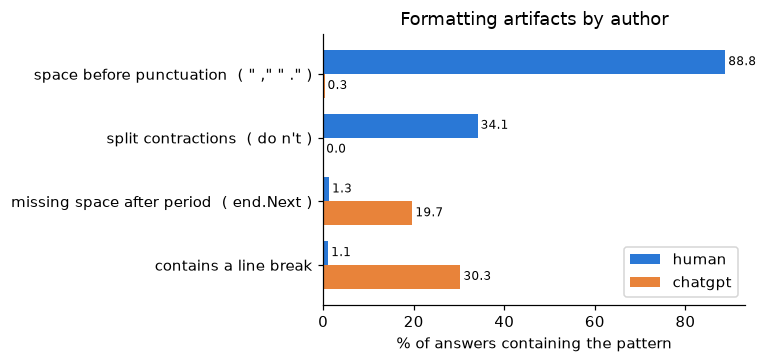

In [10]:
ax = art.plot.barh(color=[COLORS['human'], COLORS['chatgpt']], figsize=(7, 3.4), width=0.75)
ax.set_xlabel('% of answers containing the pattern'); ax.set_ylabel('')
ax.set_title('Formatting artifacts by author'); ax.invert_yaxis()
for c in ax.containers: ax.bar_label(c, fmt='%.1f', fontsize=8, padding=2)
ax.legend(['human', 'chatgpt']); plt.tight_layout(); plt.savefig(FIG / 'fig3_artifacts.png'); plt.show()

### A one-line "detector" that knows nothing about language
Rule: *if the text has a space before punctuation → human, otherwise → ChatGPT.*

In [11]:
valid = df[(df.text.str.strip() != '') & ~err_mask].drop_duplicates('text')
pred = np.where(valid.text.str.contains(r' [,.!?;:]', regex=True), 'human', 'chatgpt')
acc = (pred == valid.label).mean()
per_domain = valid.assign(ok=(pred == valid.label)).groupby('domain').ok.mean().mul(100).round(1)
print(f'Accuracy of the one-line rule: {acc:.1%}')
print(per_domain.to_string())

Accuracy of the one-line rule: 91.8%
domain
finance        55.8
medicine       59.4
open_qa        90.0
reddit_eli5    99.2
wiki_csai      52.6


**Key finding.** A trivial rule that only looks at spaces around commas is already a strong "detector".
A machine-learning model trained on the raw data would very likely learn these artifacts instead of
real differences in writing style, and its high score would be misleading.
→ **Formatting must be normalised** (detokenise human texts, restore missing spaces, remove line breaks)
before any model is trained, and we report results on both raw and cleaned data (notebook 02).

## 6. Paired questions (for a balanced dataset)

In [12]:
has = valid.groupby(['qid', 'label']).size().unstack(fill_value=0)
paired = has[(has.human > 0) & (has.chatgpt > 0)]
print(f'Questions with at least one human AND one ChatGPT answer: {len(paired):,} of {len(has):,}')
print(paired.reset_index().assign(domain=lambda x: x.qid.str.rsplit('_', n=1).str[0]).domain.value_counts().to_string())

Questions with at least one human AND one ChatGPT answer: 21,921 of 23,812
domain
reddit_eli5    14832
finance         3915
medicine        1233
open_qa         1171
wiki_csai        770


**Plan.** For each such question we keep **one human and one ChatGPT answer** →
a perfectly balanced dataset where both classes answer the same questions
(the topic cannot give the label away).

In [13]:
df.assign(is_error=err_mask).to_parquet(OUT / 'hc3_long.parquet', index=False)
print('Saved:', OUT / 'hc3_long.parquet', df.shape)

Saved: ..\data\interim\hc3_long.parquet (85449, 6)


## 7. Summary of findings

| # | Finding | Consequence for the project |
|---|---|---|
| 1 | 24k questions, 85k answers, 5 domains | Enough data for classical ML and transformer fine-tuning |
| 2 | `reddit_eli5` = ~80% of data, ~3:1 human:ChatGPT | Balance by pairing one human + one ChatGPT answer per question |
| 3 | ChatGPT answers have a narrow length range | Check how much a length-only model achieves |
| 4 | Error messages and thousands of duplicates | Remove before splitting into train/test |
| 5 | **Formatting artifacts separate the classes almost perfectly** | Normalise formatting; report raw vs. cleaned results |
| 6 | 5 distinct domains | Test generalisation: train on 4 domains, test on the 5th |